# Bands and projected DOS (Y₂Ir₂O₇)

Needs `projwfc.x` output (`<PDOS_PREFIX>.pdos_atm#...`) in `PDOS_DIR`; E_F from `SCF_OUT`. Production: projwfc.x on
the LDA+U base 8³ NSCF (job 220778, 2026-11-02, PDOS −15 to 28 eV absolute, degauss 0.003 Ry, spilling 0.0018;
step script `../validation/2026-11-02_yio_pdos/pdos.sh`). The paper version, with the Wannier bands and the VBM as
zero, is the PDOS column of `../figures/fig3.ipynb`.


In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "axion_phonon/axion.py").exists())
DATA = ROOT / "data"
sys.path.insert(0, str(ROOT))
from axion_phonon.io.qe import read_bands_out, read_kpath, fermi_energy, read_pdos_by_element

In [2]:
PREFIX = "Y2Ir2O7"
PDOS_DIR = DATA / "Y2Ir2O7/dft/base/projwfc_k8/out"   # the pdos_atm# files (projwfc.x, job 220778)
PDOS_PREFIX = "Y2Ir2O7.pdos"     # their prefix (filpdos)
SCF_OUT = DATA / "Y2Ir2O7/dft/base/scf/out/Y2Ir2O7.scf.out"   # E_F (SCF 213998, conv_thr 1e-10)
BANDS_OUT = DATA / "Y2Ir2O7/dft/base/bands/out/Y2Ir2O7.bands.out"  # pw.x bands output; None to leave the panel empty
BANDS_IN = DATA / "Y2Ir2O7/dft/base/bands/out/Y2Ir2O7.bands.in"
ORBITALS = None                  # e.g. [("Ir", "d"), ("O", "p")]; None plots every (element, orbital)
E_WINDOW = (-10.0, 6.0)          # eV relative to E_F


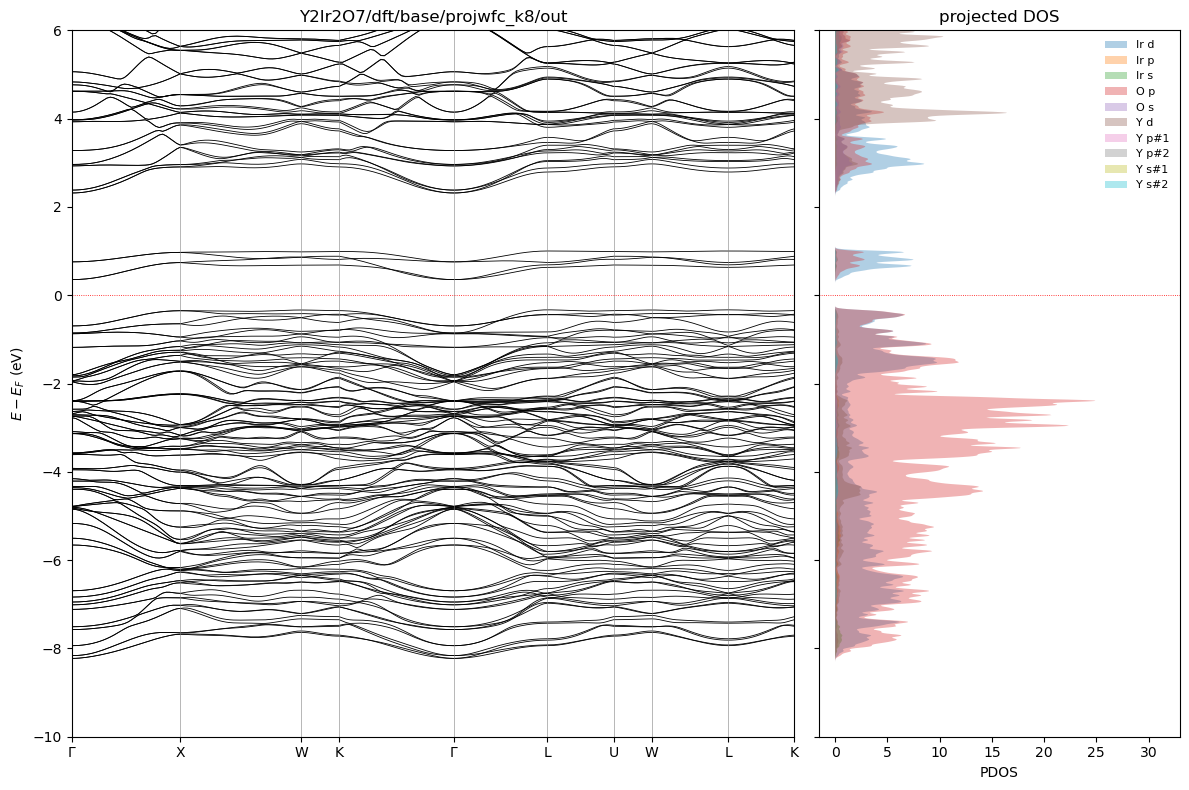

In [3]:
e_fermi = fermi_energy(SCF_OUT)
pdos = read_pdos_by_element(PDOS_DIR, PDOS_PREFIX)
if not pdos:
    raise FileNotFoundError(f"no {PDOS_PREFIX}.pdos_atm#* files in {PDOS_DIR}")

fig, (ax_b, ax_d) = plt.subplots(1, 2, figsize=(12, 8), gridspec_kw={"width_ratios": [2, 1]}, sharey=True)
if BANDS_OUT:
    k_cart, bands = read_bands_out(BANDS_OUT)
    distance = np.r_[0, np.cumsum(np.linalg.norm(np.diff(k_cart, axis=0), axis=1))]
    for band in bands:
        ax_b.plot(distance, band - e_fermi, color="black", lw=0.6)
    if BANDS_IN:
        _, ticks = read_kpath(BANDS_IN)
        ax_b.set_xticks([distance[i] for i, _ in ticks], [label for _, label in ticks])
        for i, _ in ticks:
            ax_b.axvline(distance[i], color="gray", lw=0.4)
    ax_b.set_xlim(distance[0], distance[-1])
ax_b.set(ylabel=r"$E - E_F$ (eV)", ylim=E_WINDOW, title=str(PDOS_DIR.relative_to(DATA)))
for key in ORBITALS or sorted(pdos):
    energy, dos = pdos[key]
    ax_d.fill_betweenx(energy - e_fermi, dos, alpha=0.35, label=f"{key[0]} {key[1]}")
ax_d.set(xlabel="PDOS", title="projected DOS")
ax_d.legend(frameon=False, fontsize=8)
for ax in (ax_b, ax_d):
    ax.axhline(0, color="red", lw=0.6, ls=":")
plt.tight_layout()
plt.show()